In [1]:
import numpy as np
import pandas as pd
import plt
import re
import ollama
from sklearn.metrics import confusion_matrix

In [2]:
df = pd.read_csv('.../football_games_with_2026.csv')
# Column Names: ['season', 'week', 'date', 'time_et', 'game_type', 'away', 'home', 'rank_away', 'rank_home', 'conf_away', 'conf_home', 'neutral', 'tv', 'rank_home_unranked', 'rank_away_unranked', 'home_win']

In [3]:
print(df.columns.tolist())

['season', 'week', 'date', 'time_et', 'game_type', 'away', 'home', 'rank_away', 'rank_home', 'conf_away', 'conf_home', 'neutral', 'score_away', 'score_home', 'q1_away', 'q2_away', 'q3_away', 'q4_away', 'ot_away', 'q1_home', 'q2_home', 'q3_home', 'q4_home', 'ot_home', 'first_downs_away', 'first_downs_home', 'third_down_comp_away', 'third_down_att_away', 'third_down_comp_home', 'third_down_att_home', 'fourth_down_comp_away', 'fourth_down_att_away', 'fourth_down_comp_home', 'fourth_down_att_home', 'pass_comp_away', 'pass_att_away', 'pass_yards_away', 'pass_comp_home', 'pass_att_home', 'pass_yards_home', 'rush_att_away', 'rush_yards_away', 'rush_att_home', 'rush_yards_home', 'total_yards_away', 'total_yards_home', 'fum_away', 'fum_home', 'int_away', 'int_home', 'pen_num_away', 'pen_yards_away', 'pen_num_home', 'pen_yards_home', 'possession_away', 'possession_home', 'attendance', 'tv', 'home_win']


In [4]:
print(f"{len(df):,} games, {df.shape[1]} columns")

20,731 games, 59 columns


In [5]:
print(df.describe())

             season          week    rank_away    rank_home    score_away  \
count  20731.000000  19866.000000  3537.000000  4425.000000  20234.000000   
mean    2014.390912      7.114467    13.009330    12.842260     23.623752   
std        7.182777      4.090935     7.210449     7.286595     13.744433   
min     2002.000000      0.000000     1.000000     1.000000      0.000000   
25%     2008.000000      3.000000     7.000000     6.000000     14.000000   
50%     2015.000000      7.000000    13.000000    13.000000     23.000000   
75%     2021.000000     11.000000    19.000000    19.000000     33.000000   
max     2026.000000     16.000000    25.000000    25.000000     78.000000   

         score_home       q1_away       q2_away       q3_away       q4_away  \
count  20234.000000  19789.000000  19789.000000  19787.000000  19785.000000   
mean      31.046605      5.074435      6.859568      5.343862      6.194440   
std       14.859298      5.404945      6.206526      5.523748      5.

In [6]:
df = df.copy()
has_result = df["home_win"].notna()

df["neutral"] = df["neutral"].astype(str).str.upper().isin(["TRUE", "1", "YES"])
df["date"] = pd.to_datetime(df["date"], format="mixed", errors="coerce")
df["kickoff_hour"] = pd.to_datetime(df["time_et"], format="%I:%M %p", errors="coerce").dt.hour
df["month"] = df["date"].dt.month
df["day_of_week"] = df["date"].dt.dayofweek
for c in ["rank_home", "rank_away"]:
    df[c] = pd.to_numeric(df[c], errors="coerce")

df = df.sort_values(["date", "kickoff_hour"]).reset_index(drop=True)
df["game_id"] = np.arange(len(df))

has_result = df["home_win"].notna()
print("Games with results:", has_result.sum(), "| games without results:", (~has_result).sum())
print("Seasons:", df["season"].min(), "to", df["season"].max())
df[["season", "week", "date", "kickoff_hour", "home", "away", "rank_home", "rank_away", "neutral", "home_win"]].head()

Games with results: 20234 | games without results: 497
Seasons: 2002 to 2026


,season,week,date,kickoff_hour,home,away,rank_home,rank_away,neutral,home_win
0,2002,1.0,2002-08-22,19.0,Virginia,Colorado State,NaN,NaN,False,0.0
1,2002,1.0,2002-08-23,20.0,Wisconsin,Fresno State,25.0,NaN,False,1.0
2,2002,1.0,2002-08-24,14.0,Ohio State,Texas Tech,13.0,NaN,False,1.0
3,2002,1.0,2002-08-24,16.0,NC State,New Mexico,NaN,NaN,False,1.0
4,2002,1.0,2002-08-24,19.0,Nebraska,Arizona State,10.0,NaN,False,1.0


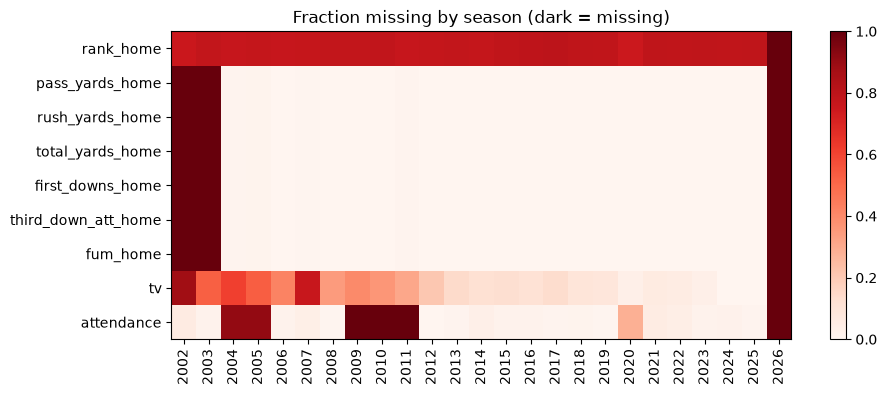

First season with box scores mostly present: 2004


In [7]:
key_cols = ["rank_home", "pass_yards_home", "rush_yards_home", "total_yards_home",
            "first_downs_home", "third_down_att_home", "fum_home", "tv", "attendance"]
key_cols = [c for c in key_cols if c in df.columns]

miss_by_season = df.groupby("season")[key_cols].apply(lambda d: d.isna().mean())

fig, ax = plt.subplots(figsize=(10, 4))
im = ax.imshow(miss_by_season.T, aspect="auto", cmap="Reds", vmin=0, vmax=1)
ax.set_yticks(range(len(key_cols)), key_cols)
ax.set_xticks(range(len(miss_by_season)), miss_by_season.index, rotation=90)
ax.set_title("Fraction missing by season (dark = missing)")
fig.colorbar(im)
plt.show()

# First season where box scores are mostly present:
good = miss_by_season["total_yards_home"] < 0.2
FIRST_FULL_SEASON = good[good].index.min()
print("First season with box scores mostly present:", FIRST_FULL_SEASON)

In [8]:
df["home_win"].value_counts(normalize=True)

home_win
1.0    0.625778
0.0    0.374222
Name: proportion, dtype: float64

# A model that predicts "home team wins" for every game would be right 62% of the time without learning anything about football. So XGBoost has to beat 62% to show it learned something.

In [9]:
df["home_ranked"] = df["rank_home"].notna()
df["away_ranked"] = df["rank_away"].notna()

summary = df.groupby(["home_ranked", "away_ranked"])["home_win"].agg(["count", "mean"])
print(summary)

                         count      mean
home_ranked away_ranked                 
False       False        13584  0.630889
            True          2225  0.267865
True        False         3113  0.878895
            True          1312  0.579268


In [10]:
print(df[["home", "away", "home_win"]].head(20))

                 home               away  home_win
0            Virginia     Colorado State       0.0
1           Wisconsin       Fresno State       1.0
2          Ohio State         Texas Tech       1.0
3            NC State         New Mexico       1.0
4            Nebraska      Arizona State       1.0
5          Iowa State      Florida State       0.0
6       Virginia Tech     Arkansas State       1.0
7              Toledo       Cal Poly SLO       1.0
8          Kent State      New Hampshire       1.0
9              Temple           Richmond       1.0
10                USF   Florida Atlantic       1.0
11      Bowling Green     Tennessee Tech       1.0
12                BYU           Syracuse       1.0
13            Buffalo             Lehigh       0.0
14   Central Michigan  Sam Houston State       1.0
15   Western Michigan      Indiana State       1.0
16  Northern Illinois        Wake Forest       1.0
17       Oregon State   Eastern Kentucky       1.0
18       Fresno State    San Di

In [11]:
played = df[has_result]
print(f"Home team wins {played['home_win'].mean():.1%} of all games  <-- 'always home' baseline")
display(played.groupby("neutral")["home_win"].agg(games="size", home_win_pct="mean"))

Home team wins 62.6% of all games  <-- 'always home' baseline


,games,home_win_pct
neutral,,
False,19203,0.631360
True,1031,0.521823


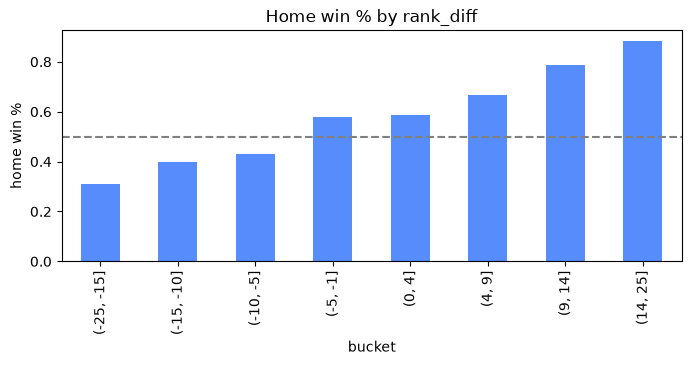

,games,home_win_pct
bucket,,
"(-25, -15]",87,0.310345
"(-15, -10]",126,0.396825
"(-10, -5]",181,0.430939
"(-5, -1]",206,0.577670
"(0, 4]",285,0.585965
"(4, 9]",213,0.666667
"(9, 14]",121,0.785124
"(14, 25]",93,0.881720


In [12]:
df["rank_diff"] = df["rank_away"] - df["rank_home"]

def binned_win_rate(data, col, bins, target="home_win", plot=True):
    """Bucket `col` and show how often the home team won in each bucket."""
    t = data.dropna(subset=[col, target]).copy()

    if t.empty:
        print(f"No games have both '{col}' and a '{target}' result, so there's nothing to plot.")
        print(f"  games with {col}: {data[col].notna().sum():,}")
        print(f"  games with a {target} result: {data[target].notna().sum():,}")
        return None

    t["bucket"] = pd.cut(t[col], bins)
    out = t.groupby("bucket", observed=True)[target].agg(games="size", home_win_pct="mean")

    if plot and not out.empty:
        ax = out["home_win_pct"].plot.bar(figsize=(8, 3), title=f"Home win % by {col}")
        ax.axhline(0.5, color="gray", ls="--")
        ax.set_ylabel("home win %")
        plt.show()
    return out

binned_win_rate(df[has_result], "rank_diff", [-25, -15, -10, -5, -1, 0, 4, 9, 14, 25])

# Data Leak Check for Game Rankings

In [13]:
# When only one team is ranked, how often does the ranked team win?
one = df[has_result & (df["rank_home"].notna() != df["rank_away"].notna())]
ranked_won = np.where(one["rank_home"].notna(), one["home_win"], 1 - one["home_win"])
print(f"Ranked team won {ranked_won.mean():.1%} of {len(one):,} ranked-vs-unranked games")

# When both are ranked, how often does the better-ranked team win?
both = df[has_result & df["rank_home"].notna() & df["rank_away"].notna() & (df["rank_home"] != df["rank_away"])]
better_won = np.where(both["rank_home"] < both["rank_away"], both["home_win"], 1 - both["home_win"])
print(f"Better-ranked team won {better_won.mean():.1%} of {len(both):,} ranked-vs-ranked games")

Ranked team won 81.8% of 5,338 ranked-vs-unranked games
Better-ranked team won 61.9% of 1,312 ranked-vs-ranked games


# Home-feild advantage

In [14]:
df["home_ranked"] = df["rank_home"].notna().astype(int)
df["away_ranked"] = df["rank_away"].notna().astype(int)

labels = {(1, 1): "both ranked", (1, 0): "only home ranked", (0, 1): "only away ranked", (0, 0): "neither ranked"}
df["matchup_type"] = [labels[(h, a)] for h, a in zip(df["home_ranked"], df["away_ranked"])]

played = df[has_result]
display(played.groupby("matchup_type")["home_win"].agg(games="size", home_win_pct="mean"))

,games,home_win_pct
matchup_type,,
both ranked,1312,0.579268
neither ranked,13584,0.630889
only away ranked,2225,0.267865
only home ranked,3113,0.878895


In [15]:
df["same_conference"] = (df["conf_home"] == df["conf_away"]).astype(int)
played = df[has_result]

for col in ["same_conference", "game_type", "week", "kickoff_hour", "day_of_week", "tv"]:
    if col in df.columns:
        print(f"\n=== {col} ===")
        display(played.groupby(col, dropna=False)["home_win"].agg(games="size", home_win_pct="mean").round(3))


=== same_conference ===


,games,home_win_pct
same_conference,,
0,8218,0.727
1,12016,0.556



=== game_type ===


,games,home_win_pct
game_type,,
post,865,0.541
regular,19369,0.630



=== week ===


...

,games,home_win_pct
kickoff_hour,,
0.0,34,0.676
1.0,2,1.000
7.0,1,0.000
8.0,1,0.000
9.0,1,0.000
10.0,3,0.333
11.0,75,0.533
12.0,3717,0.609
13.0,683,0.611



=== day_of_week ===


,games,home_win_pct
day_of_week,,
0,157,0.484
1,325,0.532
2,285,0.516
3,972,0.635
4,1156,0.560
5,17245,0.635
6,94,0.606



=== tv ===


,games,home_win_pct
tv,,
ABC,1231,0.541
ABC Regional,116,0.629
ABC and ETV,7,0.571
ACC Extra,163,0.767
ACC NETWORK,206,0.714
ACC Network,81,0.630
ASN,1,1.000
Altitude Sports,1,1.000
BIG EAST NETWORK,11,0.455


# Conference, week, game type, kickoff time

Upsets
An upset = the team with the worse rank (unranked counts as worst) wins. Only games where the ranks differ count.

What to look for: contexts where upsets happen more often (e.g. road favorites, certain weeks). Those are where the model needs more than rankings.

In [16]:
r_home = df["rank_home"].fillna(99)
r_away = df["rank_away"].fillna(99)
df["home_is_favorite"] = np.where(r_home < r_away, 1, np.where(r_away < r_home, 0, np.nan))
df["upset"] = np.where(df["home_is_favorite"].isna(), np.nan,
                       (df["home_is_favorite"] != df["home_win"]).astype(float))

played = df[has_result & df["upset"].notna()]
print(f"Overall upset rate: {played['upset'].mean():.1%} of {len(played):,} games with a ranked favorite")
for col in ["home_is_favorite", "neutral", "same_conference", "game_type"]:
    display(played.groupby(col)["upset"].agg(games="size", upset_rate="mean").round(3))

Overall upset rate: 22.2% of 6,650 games with a ranked favorite


,games,upset_rate
home_is_favorite,,
0.0,2825,0.308
1.0,3825,0.158


,games,upset_rate
neutral,,
False,6132,0.208
True,518,0.380


,games,upset_rate
same_conference,,
0,2407,0.172
1,4243,0.249


,games,upset_rate
game_type,,
post,398,0.427
regular,6252,0.208


In [17]:
POSTGAME_PREFIXES = ("score_", "q1_", "q2_", "q3_", "q4_", "ot_", "first_downs_", "third_down_", "fourth_down_",
                     "pass_", "rush_", "total_yards_", "fum_", "int_", "pen_", "possession_")
postgame_cols = [c for c in df.columns if c.startswith(POSTGAME_PREFIXES)] + ["attendance", "upset"]
postgame_cols = [c for c in postgame_cols if c in df.columns]
print(len(postgame_cols), "post-game columns that will NOT go into the model directly:")
print(postgame_cols)

46 post-game columns that will NOT go into the model directly:
['score_away', 'score_home', 'q1_away', 'q2_away', 'q3_away', 'q4_away', 'ot_away', 'q1_home', 'q2_home', 'q3_home', 'q4_home', 'ot_home', 'first_downs_away', 'first_downs_home', 'third_down_comp_away', 'third_down_att_away', 'third_down_comp_home', 'third_down_att_home', 'fourth_down_comp_away', 'fourth_down_att_away', 'fourth_down_comp_home', 'fourth_down_att_home', 'pass_comp_away', 'pass_att_away', 'pass_yards_away', 'pass_comp_home', 'pass_att_home', 'pass_yards_home', 'rush_att_away', 'rush_yards_away', 'rush_att_home', 'rush_yards_home', 'total_yards_away', 'total_yards_home', 'fum_away', 'fum_home', 'int_away', 'int_home', 'pen_num_away', 'pen_yards_away', 'pen_num_home', 'pen_yards_home', 'possession_away', 'possession_home', 'attendance', 'upset']


# Build each team's game-by-game history

In [18]:
STATS = ["score", "first_downs", "third_down_comp", "third_down_att", "pass_comp", "pass_att",
         "pass_yards", "rush_att", "rush_yards", "total_yards", "fum", "int", "pen_num", "pen_yards"]
STATS = [s for s in STATS if f"{s}_home" in df.columns]

def one_side(side, other):
    t = pd.DataFrame({
        "game_id": df["game_id"], "season": df["season"], "date": df["date"],
        "team": df[side], "opponent": df[other], "is_home": int(side == "home"),
        "won": df["home_win"] if side == "home" else 1 - df["home_win"],
    })
    for s in STATS:
        t[s] = pd.to_numeric(df[f"{s}_{side}"], errors="coerce")
        t[f"{s}_allowed"] = pd.to_numeric(df[f"{s}_{other}"], errors="coerce")
    return t

team_games = pd.concat([one_side("home", "away"), one_side("away", "home")], ignore_index=True)
team_games = team_games.sort_values(["team", "date", "game_id"]).reset_index(drop=True)

# Per-game rates (divide safely: 0 attempts -> blank instead of an error)
def ratio(a, b):
    return team_games[a] / team_games[b].replace(0, np.nan)

team_games = team_games.rename(columns={"score": "points", "score_allowed": "points_allowed"})
if "total_yards" in team_games:
    team_games["plays"] = team_games["pass_att"] + team_games["rush_att"]
    team_games["plays_allowed"] = team_games["pass_att_allowed"] + team_games["rush_att_allowed"]
    team_games["ypp"] = ratio("total_yards", "plays")                 # yards per play
    team_games["ypp_allowed"] = ratio("total_yards_allowed", "plays_allowed")
    team_games["yards_per_pass"] = ratio("pass_yards", "pass_att")
    team_games["yards_per_rush"] = ratio("rush_yards", "rush_att")
    team_games["third_down_pct"] = ratio("third_down_comp", "third_down_att")
    team_games["turnovers"] = team_games["fum"] + team_games["int"]
    team_games["takeaways"] = team_games["fum_allowed"] + team_games["int_allowed"]
    team_games["turnover_margin"] = team_games["takeaways"] - team_games["turnovers"]
team_games["point_margin"] = team_games["points"] - team_games["points_allowed"]

print(f"{len(team_games):,} team-game rows")
team_games[team_games["team"] == team_games["team"].iloc[0]].head(8)

41,462 team-game rows


,game_id,season,date,team,opponent,is_home,won,points,points_allowed,first_downs,...,plays_allowed,ypp,ypp_allowed,yards_per_pass,yards_per_rush,third_down_pct,turnovers,takeaways,turnover_margin,point_margin
0,9145,2013,2013-10-26,Abilene Christian,New Mexico State,0,0.0,29.0,34.0,21.0,...,76.0,7.863014,6.171053,8.734694,6.083333,0.285714,2.0,3.0,1.0,-5.0
1,9471,2014,2014-08-27,Abilene Christian,Georgia State,0,0.0,37.0,38.0,26.0,...,82.0,6.552632,6.902439,10.075000,2.638889,0.500000,1.0,3.0,2.0,-1.0
2,9666,2014,2014-09-13,Abilene Christian,Troy,0,1.0,38.0,35.0,26.0,...,67.0,6.662162,6.223881,9.176471,4.525000,0.428571,2.0,0.0,-2.0,3.0
3,10355,2015,2015-09-03,Abilene Christian,Fresno State,0,0.0,13.0,34.0,15.0,...,84.0,3.337838,5.261905,4.733333,1.172414,0.294118,2.0,3.0,1.0,-21.0
4,11250,2016,2016-09-03,Abilene Christian,Air Force,0,0.0,21.0,37.0,16.0,...,80.0,5.625000,7.525000,8.303030,2.774194,0.411765,0.0,2.0,2.0,-16.0
5,12156,2017,2017-09-02,Abilene Christian,New Mexico,0,0.0,14.0,38.0,20.0,...,58.0,3.710526,8.293103,4.981818,0.380952,0.388889,3.0,2.0,-1.0,-24.0
6,12195,2017,2017-09-09,Abilene Christian,Colorado State,0,0.0,10.0,38.0,18.0,...,78.0,4.690141,7.756410,6.022222,2.384615,0.312500,2.0,2.0,0.0,-28.0
7,13037,2018,2018-09-01,Abilene Christian,Baylor,0,0.0,27.0,55.0,19.0,...,64.0,6.955224,9.468750,6.150000,8.148148,0.400000,1.0,1.0,0.0,-28.0


# Rolling "entering the game" features (the leakage-safe part)
What this does: for each team, before each game, computes:

_l3 = average of the previous 3 games
_l5 = average of the previous 5 games
_std = season-to-date average (previous games this season only)
The key is .shift(1): it pushes everything down one row so the current game is never included in its own average. l3/l5 are allowed to reach back into last season, so week-1 games still get a value; std resets every season.

Also computed: games played so far this season and days of rest since the last game.

In [19]:
ROLL_COLS = ["points", "points_allowed", "point_margin", "won",
             "total_yards", "total_yards_allowed", "ypp", "ypp_allowed",
             "pass_yards", "rush_yards", "yards_per_pass", "yards_per_rush",
             "third_down_pct", "turnovers", "takeaways", "turnover_margin", "pen_yards"]
ROLL_COLS = [c for c in ROLL_COLS if c in team_games.columns]

by_team = team_games.groupby("team")
by_team_season = team_games.groupby(["team", "season"])

for col in ROLL_COLS:
    for n in (3, 5):
        team_games[f"{col}_l{n}"] = by_team[col].transform(lambda s: s.shift(1).rolling(n, min_periods=1).mean())
    team_games[f"{col}_std"] = by_team_season[col].transform(lambda s: s.shift(1).expanding().mean())

team_games["games_played"] = by_team_season.cumcount()
team_games["rest_days"] = by_team["date"].diff().dt.days.clip(upper=60)

FEATURES_PER_TEAM = [c for c in team_games.columns if c.endswith(("_l3", "_l5", "_std"))] + ["games_played", "rest_days"]
print(len(FEATURES_PER_TEAM), "features per team")

53 features per team


In [20]:
example_team = team_games["team"].value_counts().index[0]
team_games.loc[team_games["team"] == example_team, ["date", "opponent", "points", "points_l3", "points_std", "won", "won_std"]].head(8)

,date,opponent,points,points_l3,points_std,won,won_std
625,2002-08-31,Middle Tennessee,39.0,NaN,NaN,1.0,NaN
626,2002-09-07,Oklahoma,27.0,39.000000,39.000000,0.0,1.000000
627,2002-09-14,North Texas,33.0,33.000000,33.000000,1.0,0.500000
628,2002-09-21,Southern Miss,20.0,33.000000,33.000000,1.0,0.666667
629,2002-09-28,Arkansas,30.0,26.666667,29.750000,1.0,0.750000
630,2002-10-05,Georgia,25.0,27.666667,29.800000,0.0,0.800000
631,2002-10-19,Ole Miss,42.0,25.000000,29.000000,1.0,0.666667
632,2002-10-26,Tennessee,34.0,32.333333,30.857143,1.0,0.714286


# Put home and away side by side + difference features

In [21]:
side_feats = team_games[["game_id", "is_home"] + FEATURES_PER_TEAM]
home_f = side_feats[side_feats["is_home"] == 1].drop(columns="is_home").add_prefix("home_").rename(columns={"home_game_id": "game_id"})
away_f = side_feats[side_feats["is_home"] == 0].drop(columns="is_home").add_prefix("away_").rename(columns={"away_game_id": "game_id"})

games = df.merge(home_f, on="game_id").merge(away_f, on="game_id")

diffs = pd.DataFrame({f"diff_{f}": games[f"home_{f}"] - games[f"away_{f}"] for f in FEATURES_PER_TEAM})
games = pd.concat([games, diffs], axis=1)
diff_cols = list(diffs.columns)

print(games.shape)

(20731, 229)


#  EDA on the new features

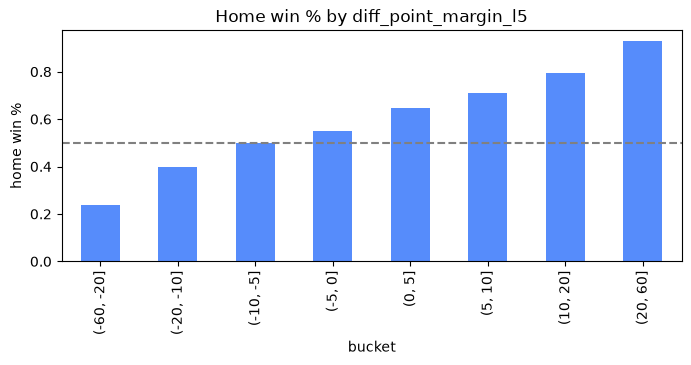

,games,home_win_pct
bucket,,
"(-60, -20]",2231,0.239803
"(-20, -10]",2762,0.399348
"(-10, -5]",1892,0.497886
"(-5, 0]",2201,0.549750
"(0, 5]",2151,0.645281
"(5, 10]",1932,0.708075
"(10, 20]",3186,0.795669
"(20, 60]",3597,0.927718


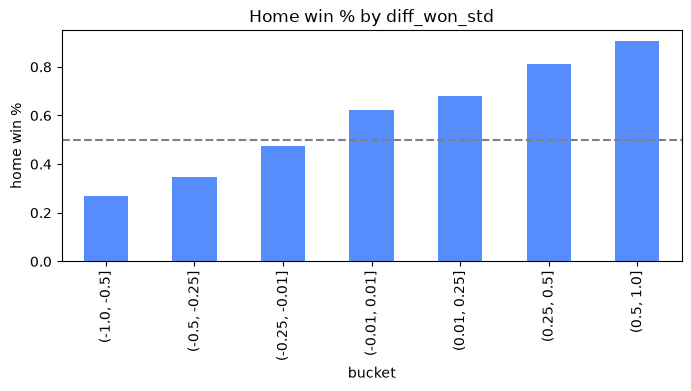

,games,home_win_pct
bucket,,
"(-1.0, -0.5]",1387,0.269647
"(-0.5, -0.25]",2336,0.347603
"(-0.25, -0.01]",2754,0.476035
"(-0.01, 0.01]",3278,0.622331
"(0.01, 0.25]",3077,0.682158
"(0.25, 0.5]",2665,0.809756
"(0.5, 1.0]",1292,0.904799


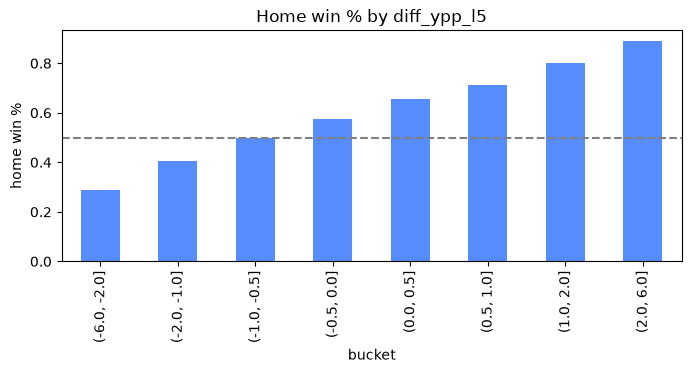

,games,home_win_pct
bucket,,
"(-6.0, -2.0]",811,0.289766
"(-2.0, -1.0]",2556,0.404538
"(-1.0, -0.5]",2236,0.496869
"(-0.5, 0.0]",2854,0.572880
"(0.0, 0.5]",2891,0.653753
"(0.5, 1.0]",2549,0.712044
"(1.0, 2.0]",3095,0.800969
"(2.0, 6.0]",1441,0.888272


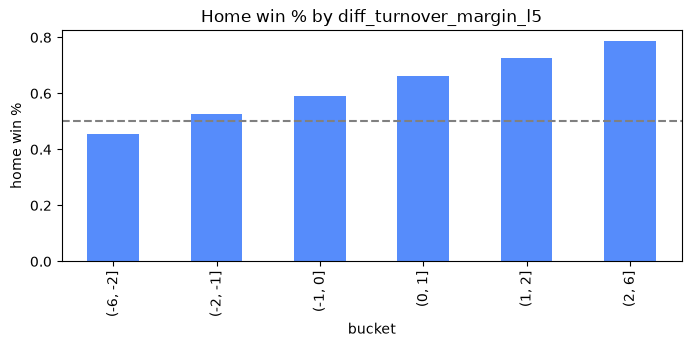

,games,home_win_pct
bucket,,
"(-6, -2]",1276,0.453762
"(-2, -1]",2957,0.526209
"(-1, 0]",5318,0.591764
"(0, 1]",5014,0.662744
"(1, 2]",2768,0.726517
"(2, 6]",1092,0.785714


In [22]:
played = games[games["home_win"].notna()]
for col, bins in [("diff_point_margin_l5", [-60, -20, -10, -5, 0, 5, 10, 20, 60]),
                  ("diff_won_std", [-1, -0.5, -0.25, -0.01, 0.01, 0.25, 0.5, 1]),
                  ("diff_ypp_l5", [-6, -2, -1, -0.5, 0, 0.5, 1, 2, 6]),
                  ("diff_turnover_margin_l5", [-6, -2, -1, 0, 1, 2, 6])]:
    if col in played:
        display(binned_win_rate(played, col, bins))

In [23]:
num = played.select_dtypes("number")
num = num.loc[:, num.std() > 0]          # skip columns that never change (correlation undefined)
corr = num.corrwith(played["home_win"]).drop("home_win").abs().sort_values(ascending=False)

print("Highest correlations (post-game columns marked):")
top = corr.head(15).to_frame("abs_corr")
top["post_game?"] = ["! POST-GAME" if c in postgame_cols else "" for c in top.index]
display(top.round(3))

windows = pd.DataFrame({w: {c: corr.get(f"diff_{c}_{w}") for c in ROLL_COLS} for w in ["l3", "l5", "std"]})
display(windows.round(3).sort_values("l5", ascending=False))

Highest correlations (post-game columns marked):


,abs_corr,post_game?
score_away,0.611,! POST-GAME
score_home,0.593,! POST-GAME
home_is_favorite,0.543,
rush_yards_away,0.453,! POST-GAME
diff_point_margin_l5,0.451,
total_yards_away,0.441,! POST-GAME
rush_yards_home,0.436,! POST-GAME
total_yards_home,0.425,! POST-GAME
diff_point_margin_l3,0.421,
diff_point_margin_std,0.408,


,l3,l5,std
point_margin,0.421,0.451,0.408
won,0.357,0.400,0.364
points,0.346,0.378,0.340
points_allowed,0.334,0.363,0.330
ypp,0.311,0.335,0.308
total_yards,0.306,0.326,0.295
ypp_allowed,0.279,0.310,0.277
total_yards_allowed,0.277,0.303,0.274
third_down_pct,0.246,0.278,0.245
yards_per_pass,0.245,0.276,0.246


# Choose model columns and split by time

Model columns = pregame context + ranking features + all the home/away/diff rolling features. Post-game columns are excluded on purpose.

Team names are left out by default (so the model learns "what makes a team win" instead of memorizing "Georgia is good"). Set USE_TEAM_NAMES = True to experiment.

Split: never random. The newest complete season is the test set, the two before it are validation (used to stop XGBoost from over-training), everything earlier is training.

In [24]:
USE_TEAM_NAMES = False
START_SEASON = games["season"].min()   # try FIRST_FULL_SEASON to use only seasons with box scores

CONTEXT = ["season", "week", "neutral", "kickoff_hour", "month", "day_of_week",
           "rank_home", "rank_away", "home_ranked", "away_ranked", "rank_diff", "same_conference"]
CATEGORICAL = ["game_type", "conf_home", "conf_away"] + (["home", "away"] if USE_TEAM_NAMES else [])

ROLLING = [f"home_{f}" for f in FEATURES_PER_TEAM] + [f"away_{f}" for f in FEATURES_PER_TEAM] + diff_cols
FEATURES = CONTEXT + CATEGORICAL + ROLLING

assert not set(FEATURES) & set(postgame_cols), "A post-game column slipped into FEATURES!"

model_df = games[(games["season"] >= START_SEASON) & games["home_win"].notna()].copy()
X = model_df[FEATURES].copy()
X["neutral"] = X["neutral"].astype(int)
for c in CATEGORICAL:
    X[c] = X[c].astype("category")
y = model_df["home_win"].astype(int)

seasons = sorted(model_df["season"].unique())
seasons = [int(s) for s in seasons if s <= 2025]
TEST_SEASONS = seasons[-1:]
VALID_SEASONS = seasons[-3:-1]
seasons = [int(s) for s in seasons]; TEST_SEASONS = [int(s) for s in TEST_SEASONS]; VALID_SEASONS = [int(s) for s in VALID_SEASONS]
tr = model_df["season"] < VALID_SEASONS[0]
va = model_df["season"].isin(VALID_SEASONS)
te = model_df["season"].isin(TEST_SEASONS)

X_tr, y_tr, X_va, y_va, X_te, y_te = X[tr], y[tr], X[va], y[va], X[te], y[te]
print(f"Train {seasons[0]}-{VALID_SEASONS[0]-1}: {len(X_tr):,} | Valid {VALID_SEASONS}: {len(X_va):,} | Test {TEST_SEASONS}: {len(X_te):,}")
print(len(FEATURES), "features")

Train 2002-2022: 17,080 | Valid [2023, 2024]: 1,829 | Test [2025]: 934
174 features


# Baselines (the "Dumb models" XGBoost has to beat)

In [25]:
from sklearn.metrics import accuracy_score, log_loss, brier_score_loss, roc_auc_score
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

def score(name, y_true, p):
    p = np.clip(np.asarray(p, dtype=float), 1e-6, 1 - 1e-6)
    return {"model": name, "accuracy": accuracy_score(y_true, p >= 0.5),
            "log_loss": log_loss(y_true, p), "brier": brier_score_loss(y_true, p),
            "auc": roc_auc_score(y_true, p) if p.std() > 0 else 0.5}

results = []

# 1. Always home: probability = training home win rate for every game
results.append(score("Always home", y_te, np.full(len(y_te), y_tr.mean())))

# 2. Rank rule: hard 0/1 picks, so only accuracy is meaningful
fav = model_df.loc[te, "home_is_favorite"].fillna(1)
results.append({"model": "Rank rule (accuracy only)", "accuracy": accuracy_score(y_te, fav)})

# 3. Logistic regression on a handful of features
LR_FEATS = [c for c in ["neutral", "home_ranked", "away_ranked", "diff_won_std", "diff_point_margin_l5", "diff_ypp_l5"] if c in X]
logreg = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(max_iter=1000))
logreg.fit(X_tr[LR_FEATS], y_tr)
results.append(score("Logistic regression", y_te, logreg.predict_proba(X_te[LR_FEATS])[:, 1]))

pd.DataFrame(results).round(3)

,model,accuracy,log_loss,brier,auc
0,Always home,0.646,0.651,0.229,0.500
1,Rank rule (accuracy only),0.687,NaN,NaN,NaN
2,Logistic regression,0.721,0.528,0.179,0.785


# XGBoost

In [26]:
from xgboost import XGBClassifier

xgb = XGBClassifier(
    n_estimators=2000, learning_rate=0.03, max_depth=4, min_child_weight=5,
    subsample=0.8, colsample_bytree=0.8,
    eval_metric="logloss", early_stopping_rounds=100,
    tree_method="hist", enable_categorical=True, random_state=42,
)
xgb.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], verbose=False)
print("Best number of trees:", xgb.best_iteration + 1)

p_xgb = xgb.predict_proba(X_te)[:, 1]
results.append(score("XGBoost", y_te, p_xgb))
pd.DataFrame(results).round(3)

Best number of trees: 247


,model,accuracy,log_loss,brier,auc
0,Always home,0.646,0.651,0.229,0.500
1,Rank rule (accuracy only),0.687,NaN,NaN,NaN
2,Logistic regression,0.721,0.528,0.179,0.785
3,XGBoost,0.746,0.495,0.166,0.817


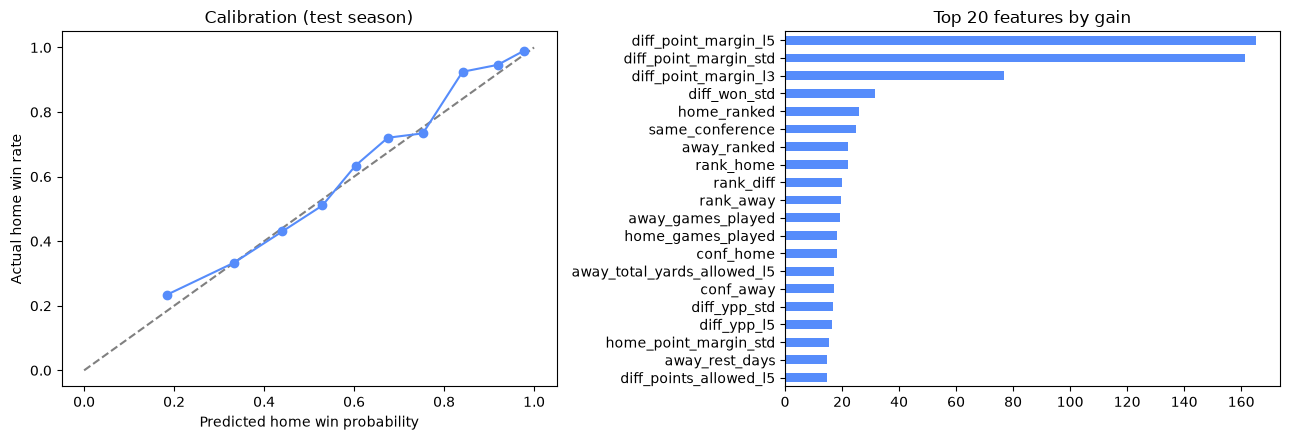

In [27]:
from sklearn.calibration import calibration_curve

frac_pos, mean_pred = calibration_curve(y_te, p_xgb, n_bins=10, strategy="quantile")
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot([0, 1], [0, 1], "--", color="gray")
axes[0].plot(mean_pred, frac_pos, "o-")
axes[0].set(xlabel="Predicted home win probability", ylabel="Actual home win rate", title="Calibration (test season)")

imp = pd.Series(xgb.get_booster().get_score(importance_type="gain")).sort_values().tail(20)
imp.plot.barh(ax=axes[1], title="Top 20 features by gain")
plt.tight_layout()
plt.show()

In [28]:
rows = []
for s in seasons[-5:]:
    trn, tst = model_df["season"] < s, model_df["season"] == s
    m = XGBClassifier(n_estimators=xgb.best_iteration + 1, learning_rate=0.03, max_depth=4, min_child_weight=5,
                      subsample=0.8, colsample_bytree=0.8, tree_method="hist", enable_categorical=True, random_state=42)
    m.fit(X[trn], y[trn])
    p = m.predict_proba(X[tst])[:, 1]
    r = score(f"XGBoost {s}", y[tst], p)
    r["always_home_acc"] = y[tst].mean()
    rows.append(r)
pd.DataFrame(rows).round(3)

,model,accuracy,log_loss,brier,auc,always_home_acc
0,XGBoost 2021,0.724,0.526,0.177,0.796,0.618
1,XGBoost 2022,0.747,0.527,0.177,0.793,0.624
2,XGBoost 2023,0.746,0.494,0.166,0.817,0.630
3,XGBoost 2024,0.726,0.520,0.177,0.795,0.630
4,XGBoost 2025,0.759,0.495,0.166,0.816,0.646


In [29]:
final_model = XGBClassifier(
    n_estimators=xgb.best_iteration + 1, learning_rate=0.03, max_depth=4, min_child_weight=5,
    subsample=0.8, colsample_bytree=0.8, tree_method="hist", enable_categorical=True, random_state=42,
)
final_model.fit(X, y)                          # every completed game, 2002 through 2025
final_model.save_model("cfb_xgb_final.json")   # saved, so you don't retrain every time
print("Final model trained on", len(X), "games")

Final model trained on 20234 games


#Code
from xgboost import XGBClassifier
final_model = XGBClassifier()
final_model.load_model("cfb_xgb_final.json")

# Kennesaw State Stats

In [30]:
print(df[df["home"].str.contains("Kennesaw", na=False)]["home"].unique())
print(df[df["away"].str.contains("Kennesaw", na=False)]["away"].unique())

<StringArray>
['Kennesaw State']
Length: 1, dtype: str
<StringArray>
['Kennesaw State']
Length: 1, dtype: str


In [31]:
ksu = df[(df["home"].str.contains("Kennesaw", na=False)) |
         (df["away"].str.contains("Kennesaw", na=False))]
print(len(ksu))
print(ksu["season"].value_counts().sort_index())
print(ksu[["home", "away"]].apply(lambda r: "home" if "Kennesaw" in r["home"] else "away", axis=1).value_counts())

43
season
2018     1
2019     1
2021     1
2022     1
2023     1
2024    12
2025    14
2026    12
Name: count, dtype: int64
away    25
home    18
Name: count, dtype: int64


# Save the model-ready table

In [32]:
out = games[["game_id", "date", "home", "away"] + FEATURES + ["home_win"]]
out.to_csv("model_ready_features.csv", index=False)
print("Saved model_ready_features.csv:", out.shape)

upcoming = games[games["home_win"].isna()]
if len(upcoming):
    Xu = upcoming[FEATURES].copy()
    Xu["neutral"] = Xu["neutral"].astype(int)
    for c in CATEGORICAL:
        Xu[c] = pd.Categorical(Xu[c], categories=X[c].cat.categories)
    upcoming = upcoming.assign(home_win_prob=xgb.predict_proba(Xu)[:, 1])
    display(upcoming[["date", "home", "away", "home_win_prob"]])

Saved model_ready_features.csv: (20731, 179)


C:\Users\cgrogan4\AppData\Local\Temp\ipykernel_34948\649892927.py:11: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  upcoming = upcoming.assign(home_win_prob=xgb.predict_proba(Xu)[:, 1])


,date,home,away,home_win_prob
20234,2026-10-07,Kennesaw State,Jacksonville State,0.445754
20235,2026-10-07,Florida International,New Mexico State,0.653408
20236,2026-10-08,Liberty,Sam Houston,0.727318
20237,2026-10-08,Western Kentucky,Missouri State,0.443197
20238,2026-10-08,Arkansas State,South Alabama,0.521376
...,...,...,...,...
20726,2026-11-28,Vanderbilt,Tennessee,0.584028
20727,2026-11-28,Virginia Tech,Virginia,0.692325
20728,2026-11-28,Wake Forest,Duke,0.609071
20729,2026-11-28,Wyoming,UConn,0.646493


In [33]:
from ollama import chat

MODEL='qwen3:4b'

def fmt(x, style):
    return "n/a" if pd.isna(x) else format(x, style)

def explain_game(home, away):
    g = upcoming[(upcoming["home"] == home) & (upcoming["away"] == away)]
    if g.empty:
        print("Game not found. Check spelling against section 17's list (home team first).")
        return
    r = g.iloc[0]

    facts = (
        f"Game: {away} at {home} on {r['date']:%b %d}" + (" (neutral site)" if r["neutral"] else "") + ".\n"
        f"Model's probability that {home} wins: {r['home_win_prob']:.0%}.\n"
        f"{home}: avg point margin last 5 games {fmt(r['home_point_margin_l5'], '+.1f')}, "
        f"win % this season {fmt(r['home_won_std'], '.0%')}, yards per play last 5 {fmt(r['home_ypp_l5'], '.1f')}.\n"
        f"{away}: avg point margin last 5 games {fmt(r['away_point_margin_l5'], '+.1f')}, "
        f"win % this season {fmt(r['away_won_std'], '.0%')}, yards per play last 5 {fmt(r['away_ypp_l5'], '.1f')}."
    )
    prompt = (
    "/no_think\n"
    "You are a college football analyst. Using ONLY the facts below, explain in 3-4 sentences "
    "why the model leans the way it does. Do not invent any stats, injuries, or players.\n\n" + facts
)

    reply = ollama.chat(model=MODEL, messages=[{"role": "user", "content": prompt}])["message"]["content"]
    reply = re.sub(r"<think>.*?</think>", "", reply, flags=re.S).strip()
    print(facts, "\n\n" + reply)

explain_game("Kennesaw State", "Jacksonville State")

Game: Jacksonville State at Kennesaw State on Oct 07.
Model's probability that Kennesaw State wins: 45%.
Kennesaw State: avg point margin last 5 games -7.6, win % this season 25%, yards per play last 5 5.4.
Jacksonville State: avg point margin last 5 games +5.6, win % this season 60%, yards per play last 5 n/a. 

The model leans toward Jacksonville State winning (55% chance) because their 60% win percentage and consistent scoring advantage (+5.6 point margin) significantly outperform Kennesaw State's 25% win percentage and large point deficits (-7.6 margin). Kennesaw State's poor win rate and heavy losses indicate systemic weakness, while Jacksonville State's strong record and positive scoring trend create a clear mismatch. This contrast explains why Kennesaw State only has a 45% probability to win.


In [34]:
cols = ["date", "week", "home", "away", "neutral", "home_win_prob",
        "home_point_margin_l5", "away_point_margin_l5", "home_won_std", "away_won_std",
        "home_ypp_l5", "away_ypp_l5"]
upcoming[cols].to_csv("predictions_2026.csv", index=False)
print("Saved", len(upcoming), "games")

Saved 497 games
